<a href="https://colab.research.google.com/github/RajeshworM/Yield_Modelling_Automation/blob/main/Crop_cluster_MP_SY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Districts found: 51


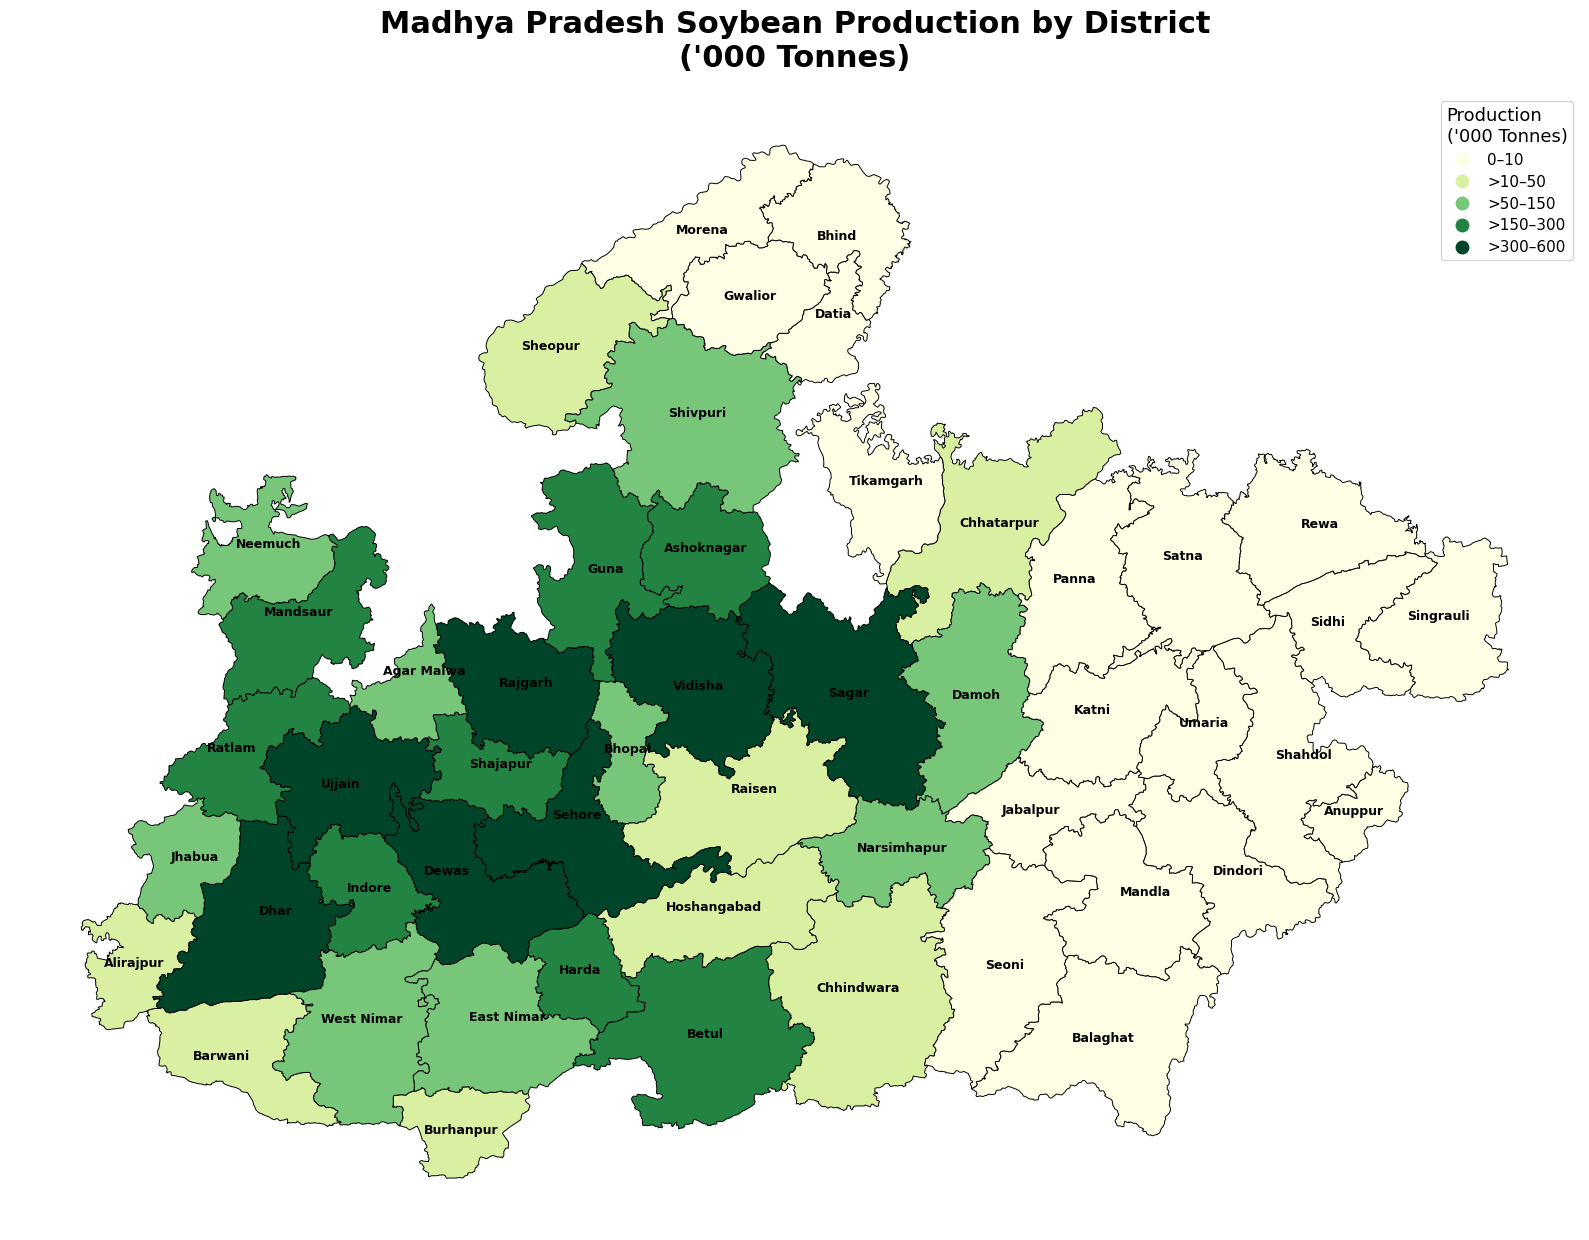


Map saved successfully:
MP_Soybean_Production_Cluster_Map.png


In [5]:
# ==========================================================
# MADHYA PRADESH SOYBEAN PRODUCTION CLUSTER MAP
# SINGLE RUN GOOGLE COLAB SCRIPT
# ==========================================================

!pip -q install geopandas mapclassify requests

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
import zipfile

# ==========================================================
# DOWNLOAD INDIA DISTRICT SHAPEFILE (GADM)
# ==========================================================

url = "https://geodata.ucdavis.edu/gadm/gadm4.1/shp/gadm41_IND_shp.zip"

print("Downloading district boundaries...")

r = requests.get(url)

with open("india.zip","wb") as f:
    f.write(r.content)

with zipfile.ZipFile("india.zip","r") as z:
    z.extractall("india")

# ==========================================================
# READ DISTRICT BOUNDARIES
# ==========================================================

gdf = gpd.read_file("india/gadm41_IND_2.shp")

# ==========================================================
# MADHYA PRADESH ONLY
# ==========================================================

mp = gdf[gdf["NAME_1"]=="Madhya Pradesh"].copy()

print("Districts found:",len(mp))

# ==========================================================
# SOYBEAN PRODUCTION DATA ('000 Tonnes)
# ==========================================================

data = {
'Agar Malwa':141.00,
'Alirajpur':46.71,
'Anuppur':3.29,
'Ashoknagar':214.32,
'Barwani':39.21,
'Betul':193.57,
'Bhopal':113.47,
'Burhanpur':15.91,
'Chhatarpur':16.28,
'Chhindwara':24.37,
'Damoh':52.74,
'Datia':0.07,
'Dewas':342.14,
'Dhar':436.22,
'Dindori':5.54,
'Guna':173.02,
'Gwalior':0.51,
'Harda':179.86,
'Hoshangabad':41.65,
'Indore':273.55,
'Jabalpur':0.98,
'Jhabua':71.46,
'Khandwa':124.84,
'Khargone':103.43,
'Mandla':0.04,
'Mandsaur':254.12,
'Morena':1.39,
'Narsinghpur':54.45,
'Neemuch':117.73,
'Panna':0.66,
'Raisen':40.96,
'Rajgarh':410.71,
'Ratlam':278.42,
'Rewa':0.29,
'Sagar':308.37,
'Satna':0.96,
'Sehore':300.45,
'Seoni':0.73,
'Shahdol':4.49,
'Shajapur':244.02,
'Sheopur':10.72,
'Shivpuri':101.88,
'Tikamgarh':3.39,
'Ujjain':580.25,
'Umaria':0.60,
'Vidisha':398.36
}

df = pd.DataFrame(
    list(data.items()),
    columns=["District","Production"]
)

# ==========================================================
# DISTRICT NAME MATCHING
# ==========================================================

name_map = {
    "East Nimar":"Khandwa",
    "West Nimar":"Khargone",
    "Narsimhapur":"Narsinghpur",
    "Hoshangabad":"Hoshangabad"
}

mp["District"] = mp["NAME_2"].replace(name_map)

# ==========================================================
# MERGE
# ==========================================================

mp = mp.merge(
    df,
    on="District",
    how="left"
)

# Missing districts = 0 production
mp["Production"] = mp["Production"].fillna(0)

# ==========================================================
# PRODUCTION CLASSES
# ==========================================================

mp["Cluster"] = pd.cut(
    mp["Production"],
    bins=[-1,10,50,150,300,600],
    labels=[
        "0–10",
        ">10–50",
        ">50–150",
        ">150–300",
        ">300–600"
    ]
)

# ==========================================================
# PROJECT CRS
# ==========================================================

mp = mp.to_crs(epsg=3857)

# ==========================================================
# PLOT MAP
# ==========================================================

fig, ax = plt.subplots(figsize=(16,16))

mp.plot(
    column="Cluster",
    cmap="YlGn",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    ax=ax
)

# ==========================================================
# LEGEND TITLE
# ==========================================================

leg = ax.get_legend()

if leg:
    leg.set_title("Production\n('000 Tonnes)")

    for txt in leg.get_texts():
        txt.set_fontsize(11)

    leg.get_title().set_fontsize(13)

# ==========================================================
# DISTRICT LABELS
# ==========================================================

for idx,row in mp.iterrows():

    try:
        p = row.geometry.representative_point()

        ax.annotate(
            row["NAME_2"],
            (p.x,p.y),
            fontsize=9,
            fontweight='bold',
            ha='center'
        )

    except:
        pass

# ==========================================================
# TITLE
# ==========================================================

ax.set_title(
    "Madhya Pradesh Soybean Production by District\n('000 Tonnes)",
    fontsize=22,
    fontweight='bold',
    pad=20
)

ax.axis('off')

plt.tight_layout()

# ==========================================================
# SAVE FIGURE
# ==========================================================

plt.savefig(
    "MP_Soybean_Production_Cluster_Map.png",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

print("\nMap saved successfully:")
print("MP_Soybean_Production_Cluster_Map.png")